# Heart Disease Prediction

Team project (4 members): predict whether a patient has heart disease from 13 clinical measurements, and compare five classification models.

This notebook re-runs the project's methodology end to end on the UCI Heart Disease (Cleveland) dataset:
75/25 train-test split, five models, accuracy, confusion matrix and k-fold cross-validation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

URL = "https://raw.githubusercontent.com/sharmaroshan/Heart-UCI-Dataset/master/heart.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## 1. Data check

In [2]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print()
print(df["target"].value_counts().rename({0: "target = 0", 1: "target = 1"}))
df.describe().T[["mean", "min", "max"]]

Missing values: 0
Duplicate rows: 1

target
target = 1    165
target = 0    138
Name: count, dtype: int64


,mean,min,max
age,54.366337,29.0,77.0
sex,0.683168,0.0,1.0
cp,0.966997,0.0,3.0
trestbps,131.623762,94.0,200.0
chol,246.264026,126.0,564.0
fbs,0.148515,0.0,1.0
restecg,0.528053,0.0,2.0
thalach,149.646865,71.0,202.0
exang,0.326733,0.0,1.0
oldpeak,1.039604,0.0,6.2


## 2. Which features move with the target?

Absolute correlation with `target` (the sign depends on how the labels are coded in this CSV copy, so only the strength is compared).

exang       0.437
cp          0.434
oldpeak     0.431
thalach     0.422
ca          0.392
slope       0.346
thal        0.344
sex         0.281
age         0.225
trestbps    0.145
restecg     0.137
chol        0.085
fbs         0.028
Name: target, dtype: float64


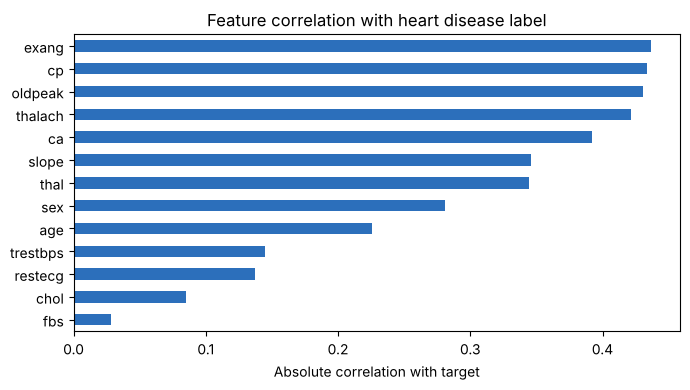

In [3]:
corr = df.corr()["target"].drop("target")
strength = corr.abs().sort_values(ascending=False)
print(strength.round(3))

plt.figure(figsize=(7, 4))
strength.sort_values().plot(kind="barh", color="#2c6fbb")
plt.xlabel("Absolute correlation with target")
plt.title("Feature correlation with heart disease label")
plt.tight_layout()
plt.show()

## 3. Train five models

Split: 75% train, 25% test. Scaling is applied inside a pipeline, so it is fitted on the training data only (matters for KNN, SVM and Logistic Regression).

In [4]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM":                 make_pipeline(StandardScaler(), SVC()),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}

rows = []
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    rows.append((name, accuracy_score(y_test, model.predict(X_test))))

results = pd.DataFrame(rows, columns=["Model", "Test accuracy"]).sort_values("Test accuracy", ascending=False)
results["Test accuracy"] = (results["Test accuracy"] * 100).round(1)
results.reset_index(drop=True)

Train: (227, 13)  Test: (76, 13)


,Model,Test accuracy
0,Random Forest,78.9
1,Logistic Regression,76.3
2,SVM,76.3
3,KNN,76.3
4,Decision Tree,72.4


## 4. More reliable comparison: 5-fold cross-validation

With only 303 patients, one train-test split can be lucky or unlucky. Cross-validation averages over five different splits.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    cv_rows.append((name, scores.mean() * 100, scores.std() * 100))

cv_results = (pd.DataFrame(cv_rows, columns=["Model", "CV mean accuracy (%)", "CV std (%)"])
              .sort_values("CV mean accuracy (%)", ascending=False)
              .round(1).reset_index(drop=True))
cv_results

,Model,CV mean accuracy (%),CV std (%)
0,Logistic Regression,84.2,4.5
1,SVM,82.2,5.3
2,Random Forest,81.9,4.4
3,KNN,79.8,7.1
4,Decision Tree,72.9,6.5


In [6]:
# Repeat the 75/25 split 30 times with different seeds
rng_scores = {name: [] for name in models}
for seed in range(30):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=seed, stratify=y)
    for name, model in models.items():
        model.fit(Xtr, ytr)
        rng_scores[name].append(accuracy_score(yte, model.predict(Xte)))

rep = pd.DataFrame({
    "Model": list(rng_scores),
    "Mean accuracy over 30 splits (%)": [np.mean(v) * 100 for v in rng_scores.values()],
    "Std (%)": [np.std(v) * 100 for v in rng_scores.values()],
}).sort_values("Mean accuracy over 30 splits (%)", ascending=False).round(1).reset_index(drop=True)
rep

,Model,Mean accuracy over 30 splits (%),Std (%)
0,SVM,83.7,3.6
1,Logistic Regression,83.5,3.9
2,Random Forest,83.4,3.5
3,KNN,83.0,3.8
4,Decision Tree,75.0,4.9


## 5. Confusion matrix of the best model on the test split

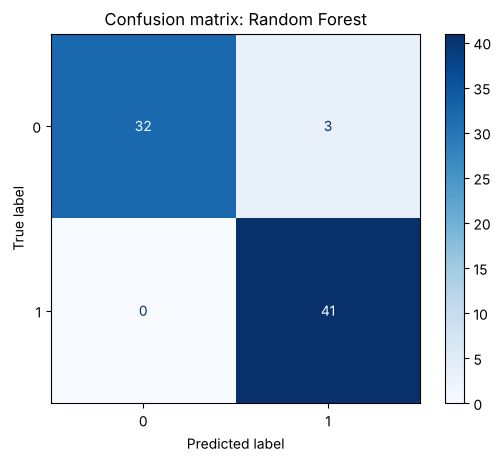

[[32  3]
 [ 0 41]]


In [7]:
best_name = results.iloc[0]["Model"]
best = fitted[best_name]
cm = confusion_matrix(y_test, best.predict(X_test))
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.title(f"Confusion matrix: {best_name}")
plt.show()
print(cm)

## 6. Summary

In [8]:
print(f"Best on the single 75/25 split : {results.iloc[0]['Model']} ({results.iloc[0]['Test accuracy']}%)")
print(f"Best on 5-fold cross-validation  : {cv_results.iloc[0]['Model']} ({cv_results.iloc[0]['CV mean accuracy (%)']}%)")
print(f"Best on 30 repeated splits       : {rep.iloc[0]['Model']} ({rep.iloc[0]['Mean accuracy over 30 splits (%)']}%)")
print()
print("Strongest features by |correlation|:", ", ".join(strength.index[:3]))

Best on the single 75/25 split : Random Forest (78.9%)
Best on 5-fold cross-validation  : Logistic Regression (84.2%)
Best on 30 repeated splits       : SVM (83.7%)

Strongest features by |correlation|: exang, cp, oldpeak
